In [1]:
from ase.io import read
import numpy as np
from matplotlib import pylab as plt

from ase import Atoms

from pathlib import Path
from collections import defaultdict
from itertools import combinations, permutations

from tqdm.notebook import tqdm

import seaborn as sns

import import_ipynb
import os
curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from Histogram_descriptor import Structure2Hist
from Graph_VVS3 import Graph_VVS3
from fdmnes_parser import get_ase_atoms_from_fdmnes
os.chdir(curdir)

In [2]:
# Размер учитывающегося кластера.
R_CLUSTER = 7.5
# Округление для загружаемых спектров.
ROUND=3

In [3]:
def centrete_structure(structure:Atoms, index:int)->Atoms:
    '''Returns a structure centered on the atom at the position specified by index,
       sorted by distances from zero coordinates.
       The structure is croped by r_cut.
       The central atom has coordinates (0, 0, 0)
    '''

    if not isinstance(index, int):
        raise TypeError('Incorrect index format, index must be integer')

    centreted_structure = structure.get_positions()-structure.get_positions()[index]
    distances = (centreted_structure**2).sum(axis=1)
    arrangment = np.argsort(distances)
    sorted_coords = centreted_structure[arrangment]
    sorted_atomic_species = structure.get_atomic_numbers()[arrangment]

    structure.set_positions(sorted_coords)
    structure.set_atomic_numbers(sorted_atomic_species)

    r_cut_square = R_CLUSTER**2

    del structure[distances[arrangment]>r_cut_square]

    return structure

def check_translation(arr1, arr2):
    if len(arr1) != len(arr2):
        return False, "Массивы имеют разную длину"

    forward, backward = {}, {}

    for i, (v1, v2) in enumerate(zip(arr1, arr2)):
        if v1 in forward and forward[v1] != v2:
            return False, {"position": i, "error": "Противоречие перевода", "val1": v1, "expected_val2": forward[v1], "found_val2": v2}
        
        if v2 in backward and backward[v2] != v1:
            return False, {"position": i, "error": "Значение уже используется", "val1": v1, "val2": v2, "already_mapped_to": backward[v2]}
        
        forward[v1] = v2
        backward[v2] = v1

    return True, forward


def get_all_angles_and_distances(atoms):
    '''    
    Функция возвращает вектор упорядоченных углов и расстояний в структуре.
    ВАЖНО! Чтобы найти уникальные структуры в объекте atoms, необходимо удалить поглощающий атом! 
    ВАЖНО: дескриптор занимает много памяти!
    '''
    n_atoms = len(atoms)
    indecies_combination = list(combinations(range(n_atoms),3))
    angles_indecies = np.array([list(permutations(tril,3))[:3] for tril in indecies_combination]).reshape(-1,3)
    angles = np.array(atoms.get_angles(angles_indecies))
    angles.sort()
    all_distances = atoms.get_all_distances()
    triu_idx = np.triu_indices(n=all_distances.shape[0],k=1)
    unique_distances = all_distances[triu_idx]
    unique_distances.sort()
    return np.round(np.concatenate((unique_distances,angles)),4).astype(np.float16)

# расчёт тестовой НЧ 140

In [4]:
path_to_model_140_init = Path('../source_data/simdata/140/initial.xyz')
path_to_madel_140_spectra = Path('../source_data/NP_140_spectra/')
atoms = read(path_to_model_140_init)

In [5]:
S2H = Structure2Hist(composition=['Pt'],
                     r_cut=7.5,
                     step_hist=0.001,
                     flatten=True,
                     sparse=False,
                    )

In [6]:
%%time
absorbtions, = np.where(atoms.get_atomic_numbers()==78)
n_atoms = len(atoms.get_atomic_numbers())

Graphs = []
# Метод может быть не стабилен. Время расчета ~1 мин 30 сек.

for absorbtion in tqdm(absorbtions, desc='GVS absorber calc'): # Итерируемся по поглощающим атомам 
    structure_temp = centrete_structure(atoms.copy(),int(absorbtion))   # Выставляем поглощающий атом в начало координат (0 0 0)
    del(structure_temp[0]) # Удаляем поглощающий атом, это ВАЖНО.
    Graphs.append(Graph_VVS3(structure_temp)) # Добавляем в массив результаты работы дескриптора Graph_VVS3 (возвращает структуру в стандартизированном, повернутом виде)

# Выравниваем shape массивов по самой большой подструктуре.
max_atoms_num = np.max([Graph.shape[0] for Graph in Graphs])
gr = np.zeros((len(Graphs),max_atoms_num,4))
for idx in tqdm(np.arange(gr.shape[0]),desc='Standartizetions'):
    gr[idx,:Graphs[idx].shape[0],:] = Graphs[idx]

# Ищем уникальные подструктуры
# unique - уникальные объекты, в данном случае стандартизированные структуры Graph_VVS3
# index - по существу не нужен, возвращаются индексы `ar`, которые приводят к созданию уникального массива (gvs_inverse[gvs_index[i]]=i)
# inverse - массив индексов уникальных подструктур размера исходной последовательности, необходим для обратной реконструкции исходного массива.
# counts - кол-во вхождений уникальных подструктур(векторов) в исходный массив.
gvs_unique,gvs_index,gvs_inverse,gvs_counts = np.unique(gr,return_index=True,return_inverse = True,return_counts=True,axis=0)
print(f'Num of unique groups by GVS = {gvs_index.shape}')

GVS absorber calc:   0%|          | 0/923 [00:00<?, ?it/s]

Standartizetions:   0%|          | 0/923 [00:00<?, ?it/s]

Num of unique groups by GVS = (23,)
CPU times: total: 8min 51s
Wall time: 1min 6s


In [7]:
%%time
# Расчет гистограмм. Время <10 s.
hist_d_140 = S2H.create(atoms, positions='Pt')
# Ищем уникальные подструктуры
hist_unique,hist_index,hist_inverse,hist_counts = np.unique(hist_d_140,return_index=True,return_inverse = True,return_counts=True,axis=0)
print(f'Num of unique groups by hist = {hist_index.shape}')

Num of unique groups by hist = (23,)
CPU times: total: 5.39 s
Wall time: 5.38 s


In [8]:
%%time
Angles_dist = []
# Аналогично Graph_VVS3, итерируемся по погл. атомам, центрируем, удаляем поглощающий, сохроняем дескриптор всех углов и расстояний.
# Самый долгий и ресурсоемкий метод. Время расчета у меня ~13-15 мин.
for absorbtion in tqdm(absorbtions, desc='AllAngDist calc'):
    structure_temp = centrete_structure(atoms.copy(),int(absorbtion))
    del(structure_temp[0])
    Angles_dist.append(get_all_angles_and_distances(structure_temp))
max_atoms_num = np.max([grp.shape[0] for grp in Angles_dist])

print(f'Длинна максимального вектора-дескриптора = {max_atoms_num}')

# Также приводим все вектора-дескрипторы к единому размеру. Внимание они БОЛЬШИЕ.
stand_mat = np.zeros((len(Angles_dist),max_atoms_num))
for zero_row, row in tqdm(zip(stand_mat, Angles_dist),desc='Standartization'):
    zero_row[0:row.shape[0]]=row.copy()

# Поиск уникальных векторов также занимает заметное время (>5 мин), что связано с их размерами.
ang_unique,ang_index,ang_inverse,ang_counts = np.unique(stand_mat,return_index=True,return_inverse = True,return_counts=True,axis=0)
print(f'Num of unique groups by All_Ang_Dist = {ang_index.shape}')

AllAngDist calc:   0%|          | 0/923 [00:00<?, ?it/s]

Длинна максимального вектора-дескриптора = 1185163


Standartization: 0it [00:00, ?it/s]

Num of unique groups by All_Ang_Dist = (23,)
CPU times: total: 18min 14s
Wall time: 18min 14s


In [9]:
%%time
# Проверка соответствия hist и GVS
success, correspond_Hist2GVS = check_translation(hist_inverse, gvs_inverse)
print(f"Hist and GVS is equal: {success}")

# Проверка соответствия hist и AAD
success, correspond_Hist2AAD = check_translation(hist_inverse, ang_inverse)
print(f"Hist and AAD is equal: {success}")

Hist and GVS is equal: True
Hist and AAD is equal: True
CPU times: total: 0 ns
Wall time: 2 ms


__________

In [10]:
# Получаем список путей к спектрам нужной модели НЧ, и сортируем их по порядку.
path_to_spectra_list = list(Path.glob(path_to_madel_140_spectra,'**/Pt.txt'))
path_to_spectra = sorted(path_to_spectra_list,key=lambda x: int(x.parent.name))
# Важно привести список путей к спектрам к виду np.ndarray, иначе дальше может вылезти ошибка.
path_to_spectra = np.array(path_to_spectra)
path_to_spectra[8:15]

array([WindowsPath('../source/NP_140_spectra/8/Pt.txt'),
       WindowsPath('../source/NP_140_spectra/9/Pt.txt'),
       WindowsPath('../source/NP_140_spectra/10/Pt.txt'),
       WindowsPath('../source/NP_140_spectra/11/Pt.txt'),
       WindowsPath('../source/NP_140_spectra/12/Pt.txt'),
       WindowsPath('../source/NP_140_spectra/13/Pt.txt'),
       WindowsPath('../source/NP_140_spectra/14/Pt.txt')], dtype=object)

In [11]:
unique = hist_unique.copy()
inverse = hist_inverse.copy().astype(int) 
# Получим список путей к спектрам внутри каждой уникальной группы
# [Group1:[path,...],Group2:[path,...],...]
group_unique_path = [path_to_spectra[np.where(inverse==i)[0]] for i in np.arange(unique.shape[0])]

# Получим массив спектров внутри каждой уникальной группы, округленные до знака ROUND 
# округляются и X и Y, правильней было бы округлять только Y, но если шаг энергии определен с меньшей точностью чем ROUND, то все нормально.
# [Group1:[spectra,...],Group2:[spectra,...],...]
group_unique_spectra = [np.array([np.round(np.loadtxt(path,skiprows=2),ROUND) for path in path_group]) for path_group in group_unique_path]

# В отдельную переменную загрузим все спектры и округлим их.
spectra = np.array([np.round(np.loadtxt(path,skiprows=2),ROUND) for path in path_to_spectra])
# Найдем уникальные спектры среди всего множества спектров. 
# Для этого сделаем спектры (2D массивы) плоскими (1D) (он вытянит оси X и Y вдоль одной оси
# Т.к. он сделает это одинаковым образом для всех спектров, то это не важно,
# Хотя по уму можно ограничиться рассмотрением только Y компоненты спектров при условии что ось энергии для всех одинакова.
spectra_ = spectra.reshape(spectra.shape[0],-1)
unique_spectra,index_spectra,inverse_spectra,counts_spectra = np.unique(spectra_,return_index=True,return_inverse = True,return_counts=True,axis=0)
print(f'Число уникальных спектров = {index_spectra.shape}')

Число уникальных спектров = (29,)


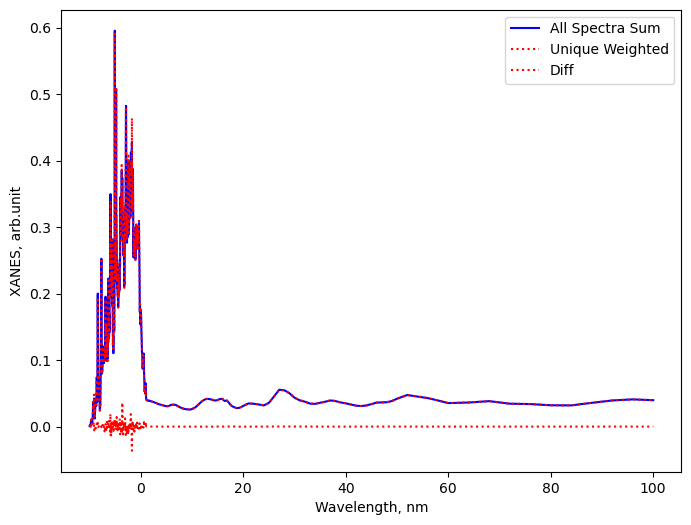

In [12]:
# Построим спектр для данной НЧ как сумму всех входящих в нее спектров, и как взвешенную сумму уникальных спектров подструктур.

X_array = spectra[0,:,0]
# Найдем спектр НЧ как усредненный по всем возможным спектрам
Y_by_all_spectra = spectra[:,:,1].mean(axis=0)

# Выделим уникальные спектры по подструктурам (каждой подструктуре ставится 1 спектр в соответствие.
Y_unique_by_hist = spectra[hist_index][:,:,1]
# Найдем их взвешенное усреднение.
hist_weights = hist_counts/hist_counts.sum(keepdims=True)
Y_weighted_by_hist = hist_weights@Y_unique_by_hist

# Построим график.
plt.figure(figsize=(8,6))
plt.plot(X_array,Y_by_all_spectra,'b-',label='All Spectra Sum')
plt.plot(X_array,Y_weighted_by_hist,'r:',label='Unique Weighted')
plt.plot(X_array,Y_by_all_spectra-Y_weighted_by_hist,'r:',label='Diff')
plt.ylabel('XANES, arb.unit')
plt.xlabel('Wavelength, nm')
plt.legend()
plt.savefig('../images/NP140_Weighted_and_Full_sum.png', dpi=600)
plt.show()

# Проверка соответствия уникальных спектров и подструктур.

In [13]:
# Соберем данные о группах спектров и группах подструктур в словарь.
# За основу берутся уникальные подструктуры определенные для НЧ.

# Создадим словарь, каждому ключу которого в соответствие ставится list.
DIF_MAT_DICT = defaultdict(list)

for idx,group in enumerate(group_unique_spectra): # Индекс группы спектров, и сама группа спектров.
    n_elements = group.shape[0]                   # Число спектров в группе.
    # Разница между всеми парами спектров
    dif_mat_X = ((group[None,:]-group[:,None])**2)[:,:,:,0].sum(axis=2)   # Разница между осями X
    dif_mat_Y = ((group[None,:]-group[:,None])**2)[:,:,:,1].sum(axis=2)   # Разница между осями Y

    # Оси X обязаны совпадать.
    assert dif_mat_X.reshape(-1).sum()==0, 'Расхождения в оси Х'
    
    unique_ = np.unique(dif_mat_Y[-1])  # Список уникальных разностей спектров (невязок) внутри  группы.
    DIF_MAT_DICT['Unique_in_group'].append(len(unique_))  # Число уникальных невязок/или спектров внутри группы
    DIF_MAT_DICT['Group_IDX'].append(idx)   # Индекс группы
    DIF_MAT_DICT['Y_DIF'].append(dif_mat_Y)  #Список невязок внутри группы.

for idx in range(len(unique)):
    un_gr_indxs = np.where(inverse==idx)
    DIF_MAT_DICT['Atom_IDX'].append(un_gr_indxs)  # Порядковые номера атомов в стурктуре соответствующие данной группе.

In [14]:
# Если все отработало правильно, то число уникальных спектров по всем группам должно быть равно index_spectra.shape (для 140 это 29)
sum(DIF_MAT_DICT['Unique_in_group'])

29

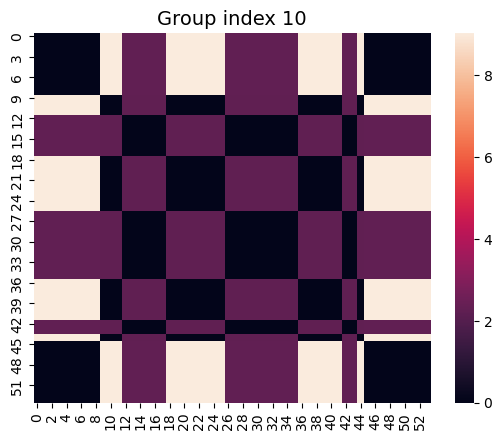

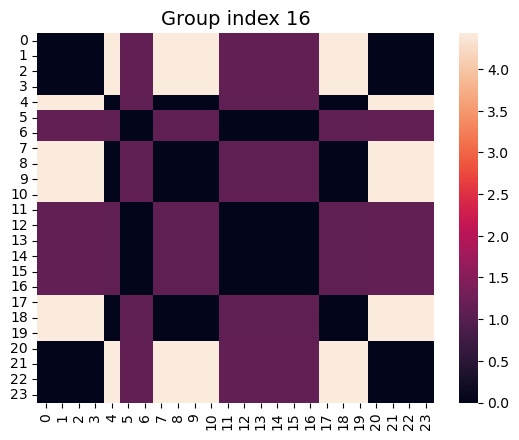

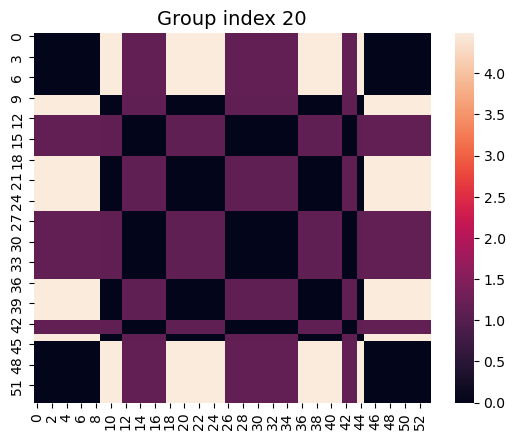

In [15]:
# Отрисовка тепловых карт невязок внутри группы. Можно посмотреть но не обязательно.
for idx,dif_mat in enumerate(DIF_MAT_DICT['Y_DIF']):
    if dif_mat.sum()>0: # Если внутри группы есть разные спектры, то суммарная невязка для всех пар будет >0.
        plt.figure()
        plt.title(f'Group index {idx}', fontsize=14)
        sns.heatmap(data=dif_mat,vmin=0, vmax=max(0.5,dif_mat.max()))#,annot=True,fmt=".3f")
        plt.show()

In [16]:
# Аналогично проверим по уникальным группам спектров.
# создадим список уникальных групп по спектрам
DIF_MAT_DICT_SPEC = defaultdict(list)
group_unique_by_spectras = []
for idx in range(len(unique_spectra)):
    un_gr_indxs = np.where(inverse_spectra==idx)
    group_unique_by_spectras.append(spectra[un_gr_indxs])
    DIF_MAT_DICT_SPEC['Atom_IDX'].append(un_gr_indxs)

for idx,group in enumerate(group_unique_by_spectras):
    n_elements = group.shape[0]
    dif_mat_X = ((group[None,:]-group[:,None])**2)[:,:,:,0].sum(axis=2)
    dif_mat_Y = ((group[None,:]-group[:,None])**2)[:,:,:,1].sum(axis=2)
    
    assert dif_mat_X.reshape(-1).sum()==0, 'Расхождения в оси Х'
    
    unique_ = np.unique(dif_mat_Y.reshape(-1))
    DIF_MAT_DICT_SPEC['Unique_in_group'].append(len(unique_))
    DIF_MAT_DICT_SPEC['Group_IDX'].append(idx)
    DIF_MAT_DICT_SPEC['Y_DIF'].append(dif_mat_Y)

In [17]:
sum(DIF_MAT_DICT_SPEC['Unique_in_group'])

29

## Посмотрим на характер соответствий между уникальными подструктурами и спектрами

In [18]:
print(f'Atomic indecies of unique group 0 by Spectra { DIF_MAT_DICT_SPEC["Atom_IDX"][0] }')
print(f'Atomic indecies of unique group 0 by Desctiptor {DIF_MAT_DICT["Atom_IDX"][0]}')

Atomic indecies of unique group 0 by Spectra (array([  3,  48,  72, 107, 419, 443, 575, 587, 875, 895, 907, 922]),)
Atomic indecies of unique group 0 by Desctiptor (array([  3,  48,  72, 107, 419, 443, 575, 587, 875, 895, 907, 922]),)


In [19]:
correspondance_dict = defaultdict(list)

for struct_group_idx,unique_by_descriptor in enumerate(DIF_MAT_DICT['Atom_IDX']):
    for spec_group_idx,unique_by_spectra in enumerate(DIF_MAT_DICT_SPEC['Atom_IDX']):
        if set(unique_by_descriptor[0])&set(unique_by_spectra[0]):
            correspondance_dict[f'Desc_{struct_group_idx}'].append(spec_group_idx)
            correspondance_dict[f'Spec_{spec_group_idx}'].append(struct_group_idx)

In [20]:
correspondance_dict

defaultdict(list,
            {'Desc_0': [0],
             'Spec_0': [0],
             'Desc_1': [2],
             'Spec_2': [1],
             'Desc_2': [3],
             'Spec_3': [2],
             'Desc_3': [1],
             'Spec_1': [3],
             'Desc_4': [9],
             'Spec_9': [4],
             'Desc_5': [8],
             'Spec_8': [5],
             'Desc_6': [12],
             'Spec_12': [6],
             'Desc_7': [10],
             'Spec_10': [7],
             'Desc_8': [4],
             'Spec_4': [8],
             'Desc_9': [11],
             'Spec_11': [9],
             'Desc_10': [5, 6, 7],
             'Spec_5': [10],
             'Spec_6': [10],
             'Spec_7': [10],
             'Desc_11': [18],
             'Spec_18': [11],
             'Desc_12': [15],
             'Spec_15': [12],
             'Desc_13': [14],
             'Spec_14': [13],
             'Desc_14': [26],
             'Spec_26': [14],
             'Desc_15': [17],
             'Spec_17': 

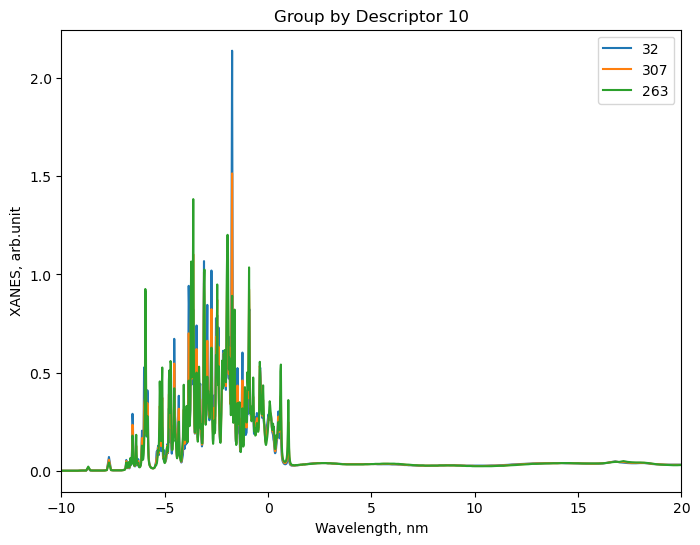

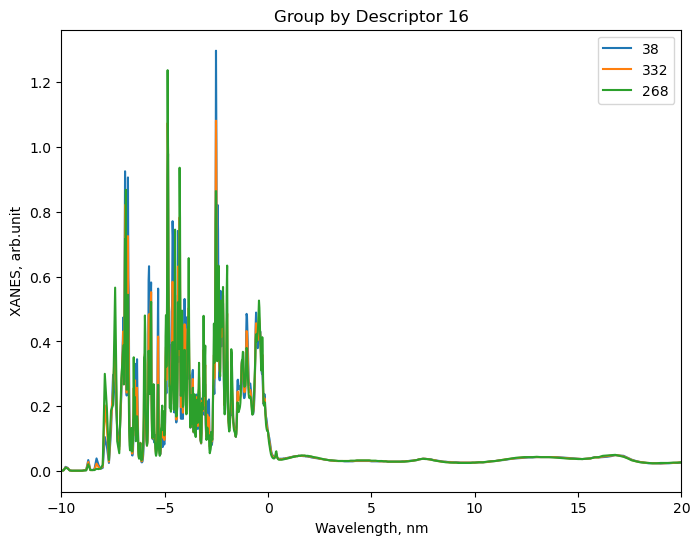

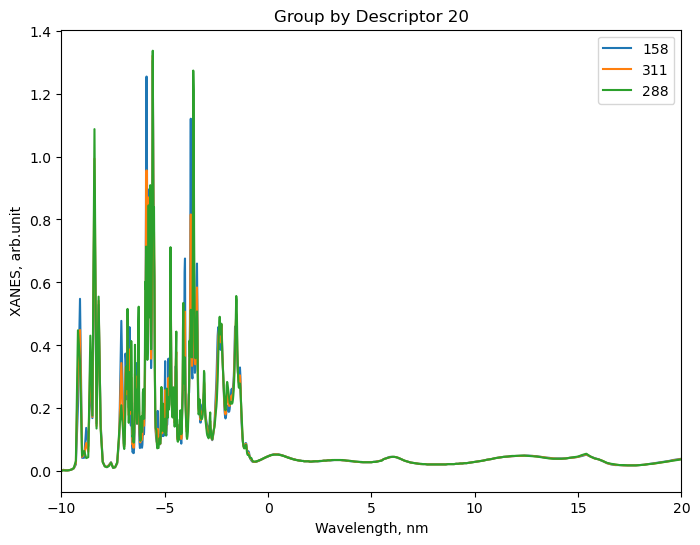

In [21]:
# Отрисуем различные спектры для тех групп, внутри которых более 1 уникального спектра.
for gr_idx in range(len(DIF_MAT_DICT['Y_DIF'])):
    u_,i_ = np.unique(DIF_MAT_DICT['Y_DIF'][gr_idx][0], return_index=True)
    r_ = DIF_MAT_DICT['Atom_IDX'][gr_idx][0][i_]
    if len(r_)>1:
        plt.figure(figsize=(8,6))
        plt.title(f'Group by Descriptor {gr_idx}')
        for idx in r_:
            plt.plot(spectra[idx][:,0],spectra[idx][:,1], label=f'{idx}')
        plt.legend()#loc="upper left", bbox_to_anchor=(1,1),fontsize=14)
        plt.xlim(-10,20)
        plt.ylabel('XANES, arb.unit')
        plt.xlabel('Wavelength, nm')
        
        plt.savefig(f'../images/NP140_dif_spectrum_group_{gr_idx}.png', dpi=600)
        
        plt.show()

## Отрисуем график соответствия уникальных подструктур и спектров

In [22]:
from matplotlib.patches import Circle
from matplotlib.lines import Line2D
from matplotlib import cm

from matplotlib.font_manager import FontProperties
font = FontProperties()
font.set_weight('bold')
font.set_size('medium')

def add_node(ax,coords:np.ndarray, radius:float, ec:str, fc:str, alpha:float, label:str):
    c = Circle(coords, radius=radius, edgecolor=ec, facecolor=fc,alpha=alpha)
    ax.add_patch(c)
    ax.text(x=coords[0],y=coords[1],s=label,horizontalalignment='center', verticalalignment='center')

def add_edge(ax, coords_1, coords_2, radius_1, radius_2, color, alpha):
    x_g = coords_2[0]-coords_1[0]
    y_g = coords_2[1]-coords_1[1]
    gip = np.sqrt(x_g**2+y_g**2)
    sin = y_g/gip
    cos = x_g/gip
    line = Line2D([coords_1[0]+radius_1*cos, coords_2[0]-radius_2*cos], [coords_1[1]+radius_1*sin, coords_2[1]-radius_2*sin], color=color, alpha=alpha)
    ax.add_line(line)

In [23]:
cor = {int(key.split('_')[-1]):val for key,val in correspondance_dict.items() if 'Desc' in key}
gvs_group_size = list(hist_counts)
spectra_group_size = list(counts_spectra)
print(cor)

{0: [0], 1: [2], 2: [3], 3: [1], 4: [9], 5: [8], 6: [12], 7: [10], 8: [4], 9: [11], 10: [5, 6, 7], 11: [18], 12: [15], 13: [14], 14: [26], 15: [17], 16: [19, 20, 21], 17: [27], 18: [28], 19: [25], 20: [22, 23, 24], 21: [16], 22: [13]}


23


C:\Users\Veretas\AppData\Local\Temp\ipykernel_13904\2409512290.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colmap = cm.get_cmap('viridis', N_i) #tab20c, viridis, magma


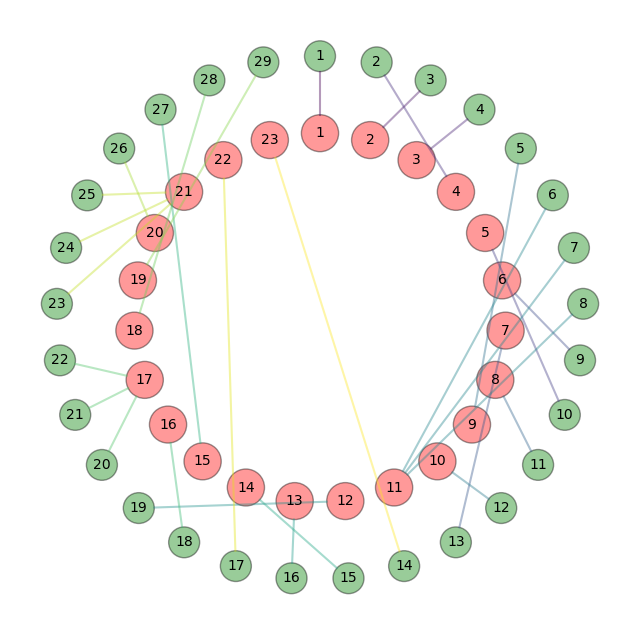

In [24]:
size = 100
r1,r2 = 6,5

R_internal = 60
R_external = 85
N_i, N_e = len(gvs_group_size), len(spectra_group_size)
print(N_i)
alpha=0.4

colmap = cm.get_cmap('viridis', N_i) #tab20c, viridis, magma

internal_angles = np.linspace(2*np.pi+np.pi/2, np.pi/2, N_i+1)
external_angles = np.linspace(2*np.pi+np.pi/2, np.pi/2, N_e+1)

fig, ax = plt.subplots()
fig.set_figwidth(8)
fig.set_figheight(8)

ax.set_xlim(-size,size)
ax.set_ylim(-size,size)
ax.axis('off')

coord_internal = []

for num,i in enumerate(internal_angles[:-1]):
    x = R_internal*np.cos(i)
    y = R_internal*np.sin(i)
    
    coord_internal.append((x,y))
    
    add_node(ax, coords=(x,y), radius=r1, ec='black', fc='red', alpha=alpha, label=str(num+1))
    
coord_external = []

for num,i in enumerate(external_angles[:-1]):
    x = R_external*np.cos(i)
    y = R_external*np.sin(i)
    
    coord_external.append((x,y))
    
    add_node(ax, coords=(x,y), radius=r2, ec='black', fc='green', alpha=alpha, label=str(num+1))
    
for i,internal in enumerate(cor):
    color=colmap.colors[i]
    for external in cor[internal]:
        add_edge(ax, coords_1=coord_internal[internal], coords_2=coord_external[external],radius_1=r1, radius_2=r2, color=color, alpha=alpha)
    
plt.savefig('../images/Correspondence_substructures_spectra_plt.png', dpi=600)

plt.show()

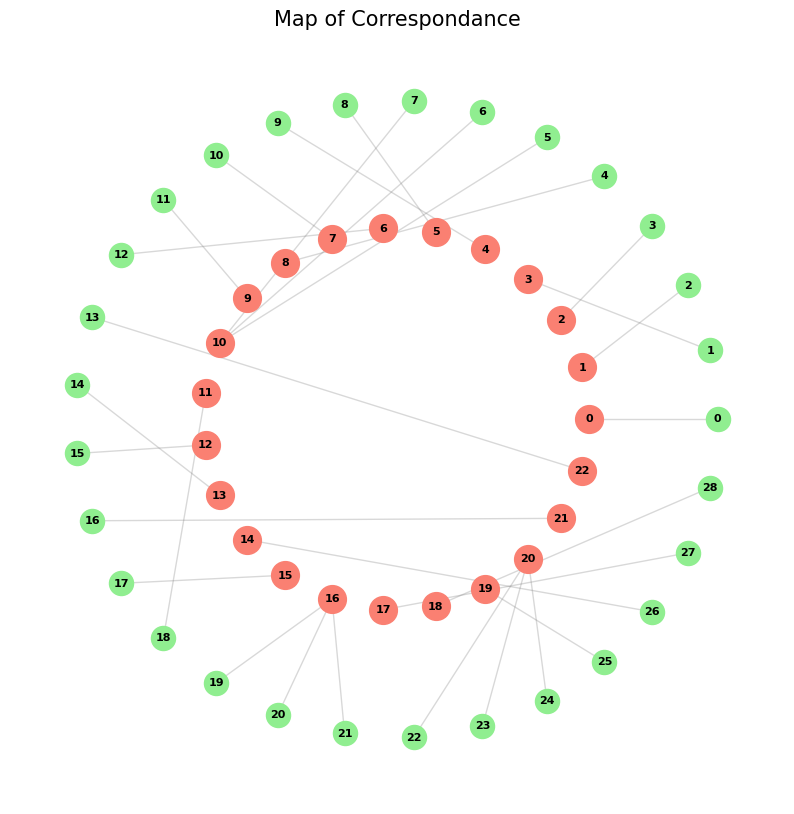

In [25]:
import networkx as nx

# Создаем граф
G = nx.Graph()

# Добавляем ребра и определяем множества узлов
left_nodes = list(cor.keys())
right_nodes = sorted(list(set([v for sublist in cor.values() for v in sublist])))

for k, vs in cor.items():
    for v in vs:
        # Добавляем префикс, чтобы узлы с одинаковыми ID не слились
        G.add_edge(f"L{k}", f"R{v}")

# Генерируем позиции: два концентрических кольца
pos = {}
# Внутреннее кольцо (L)
pos.update((f"L{n}", np.array([0.6 * np.cos(2*np.pi*i/len(left_nodes)), 
                               0.6 * np.sin(2*np.pi*i/len(left_nodes))])) 
           for i, n in enumerate(left_nodes))
# Внешнее кольцо (R)
pos.update((f"R{n}", np.array([1.0 * np.cos(2*np.pi*i/len(right_nodes)), 
                               1.0 * np.sin(2*np.pi*i/len(right_nodes))])) 
           for i, n in enumerate(right_nodes))

plt.figure(figsize=(10, 10))
ax = plt.gca()

# Рисуем связи (прозрачные дуги выглядят лучше прямых)
nx.draw_networkx_edges(G, pos, alpha=0.3, edge_color='gray', width=1)

# Рисуем узлы внутреннего кольца
nx.draw_networkx_nodes(G, pos, nodelist=[f"L{n}" for n in left_nodes], 
                       node_color='salmon', node_size=400, label='Internal')
# Рисуем узлы внешнего кольца
nx.draw_networkx_nodes(G, pos, nodelist=[f"R{n}" for n in right_nodes], 
                       node_color='lightgreen', node_size=300, label='External')

# Добавляем подписи (убираем префиксы L и R для чистоты)
labels = {n: n[1:] for n in G.nodes()}
nx.draw_networkx_labels(G, pos, labels, font_size=8, font_weight='bold')

plt.title("Map of Correspondance", fontsize=15)
plt.axis('off')

plt.savefig('../images/Correspondence_substructures_spectra_nxgraph.png', dpi=600)

plt.show()

## Проверим входных структур в FDMNESS (мало ли там закралась ошибка).
### Логика проверки такая же как для поиска подструктур внутри НЧ.

In [26]:
# Получение путей к входным файлам FDMNESS расчетов для проверки.
path_to_input_FDMNES = list(Path.glob(path_to_madel_140_spectra,'**/Pt.inp'))
path_to_input_FDMNES = sorted(path_to_input_FDMNES,key=lambda x: int(x.parent.name))

In [27]:
difs_fdmness = []
for group in tqdm(DIF_MAT_DICT['Atom_IDX']):
    group_0_FDMNES = [get_ase_atoms_from_fdmnes(path_to_input_FDMNES[idx]) for idx in group[0]]
    # S2H.create можно заменить на GVS или AAD
    hist_diffs = np.array([S2H.create(atom,0) for atom in group_0_FDMNES]).reshape(len(group_0_FDMNES),-1)
    difs_fdmness.append(((hist_diffs[None,:]-hist_diffs[:,None])**2).flatten().sum())

difs_fdmness = np.array(difs_fdmness)

print(len(difs_fdmness))
print(f'all diffs is 0 : {all(0==difs_fdmness)}')
print(difs_fdmness)

  0%|          | 0/23 [00:00<?, ?it/s]

23
all diffs is 0 : True
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
